# multiple regression 

In [1]:
# libraries 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# read dataset

df_index = pd.read_csv("C:\\Users\\lenovo\\Downloads\\economic_index.csv")

In [3]:
df_index

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256
5,5,2017,7,2.50,5.6,1254
6,6,2017,6,2.50,5.5,1234
7,7,2017,5,2.25,5.5,1195
8,8,2017,4,2.25,5.5,1159
9,9,2017,3,2.25,5.6,1167


In [4]:
# drop unccessary column 

df_index.drop( columns = ["Unnamed: 0" , "year","month"], axis = 1 , inplace =True)
df_index

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256
5,2.50,5.6,1254
6,2.50,5.5,1234
7,2.25,5.5,1195
8,2.25,5.5,1159
9,2.25,5.6,1167


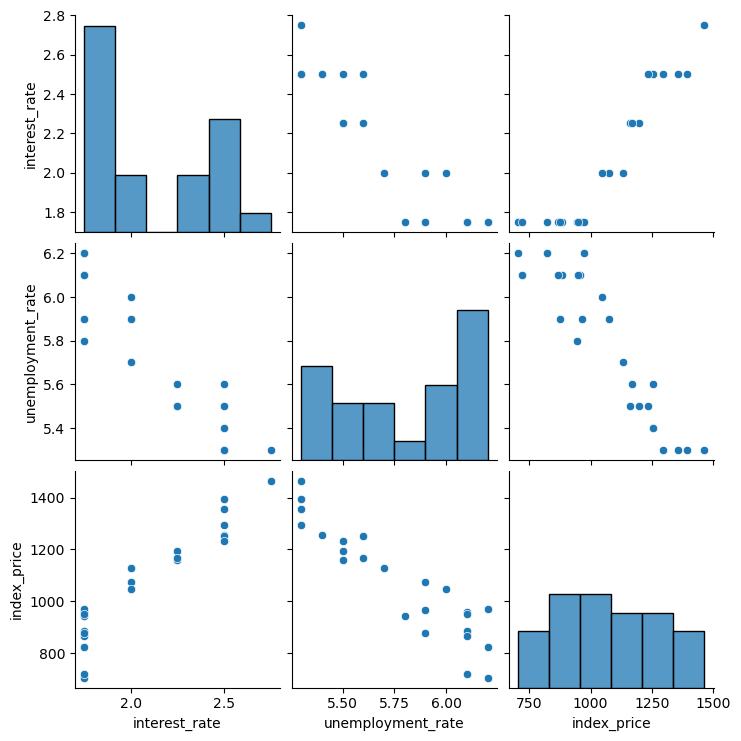

In [7]:
# do some visualzation 

import seaborn as sns
sns.pairplot(df_index)

In [8]:
## check for null values :

df_index.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

In [9]:
## correlation 

df_index.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


Text(0, 0.5, 'unenployment rate')

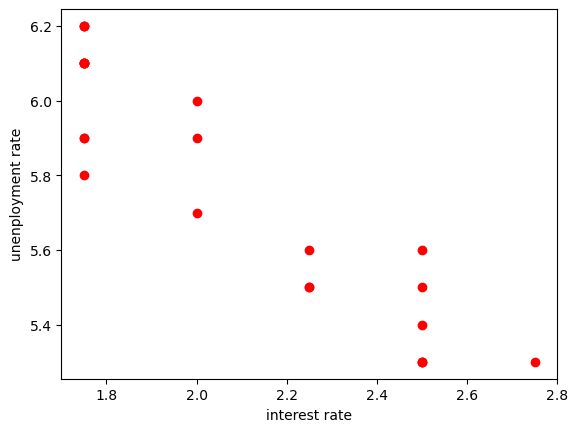

In [15]:
# close visualization :

plt.scatter(df_index["interest_rate"],df_index["unemployment_rate"] , color = "r")
plt.xlabel("interest rate")
plt.ylabel("unenployment rate")

In [19]:
# lets seperate , the dependent and independent feature,
X = df_index.iloc[:,:-1]
y = df_index.iloc[:,-1]


In [20]:
X

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4
5,2.50,5.6
6,2.50,5.5
7,2.25,5.5
8,2.25,5.5
9,2.25,5.6


In [21]:
y

0     1464
1     1394
2     1357
3     1293
4     1256
5     1254
6     1234
7     1195
8     1159
9     1167
10    1130
11    1075
12    1047
13     965
14     943
15     958
16     971
17     949
18     884
19     866
20     876
21     822
22     704
23     719
Name: index_price, dtype: int64

In [39]:
# lets make traning and testing data 

from sklearn.model_selection import train_test_split

X_train, X_test , y_train , y_test  = train_test_split(X, y , test_size = 0.25 , random_state =42)

In [40]:
X_train.shape

(18, 2)

In [41]:
X_test.shape

(6, 2)

In [42]:
import seaborn as sns 


<Axes: xlabel='interest_rate', ylabel='index_price'>

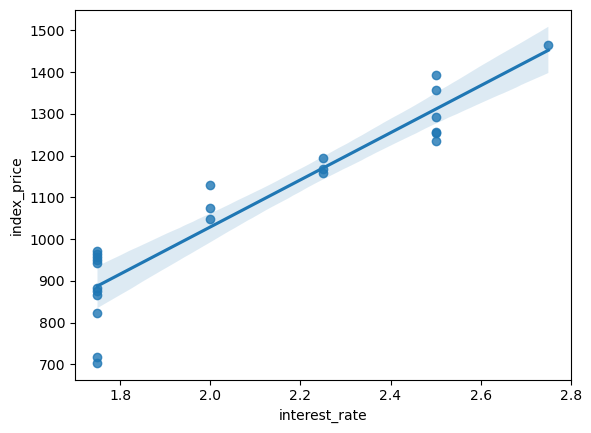

In [43]:
sns.regplot(x = df_index["interest_rate"],y = df_index["index_price"])          # it plot data in linear model 

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

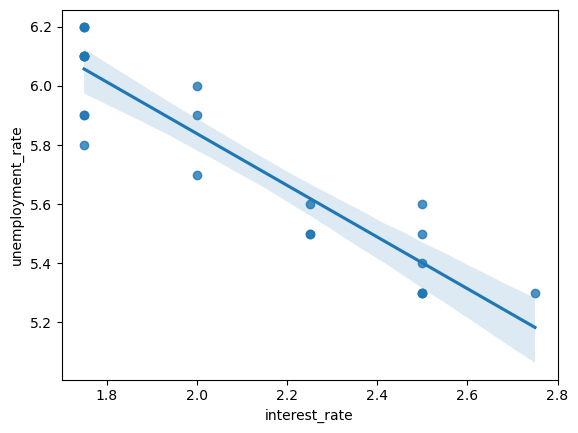

In [44]:
sns.regplot(x = df_index["interest_rate"],y = df_index["unemployment_rate"])          # it plot data in linear model 

**you are able to get regression line in this plot,** 


In [45]:
#standard scaling  , 

from sklearn.preprocessing import StandardScaler

In [46]:
scaler = StandardScaler()

In [47]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)

In [48]:
X_train

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [49]:
X_test

array([[ 0.36115756, -0.82078268],
       [-1.08347268,  1.33377186],
       [ 1.8057878 , -1.43636969],
       [-1.08347268,  1.02597835],
       [-0.36115756,  0.41039134],
       [ 0.36115756, -0.51298918]])

In [50]:
from sklearn.linear_model import LinearRegression

In [51]:
regression = LinearRegression()